## Cell 1: Import libraries and load predictions

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

PROCESSED_DIR = Path("../data/processed")

sns.set_style("whitegrid")

In [11]:
df = pd.read_csv(
    PROCESSED_DIR / "evaluation_predictions.csv"
)

print("Evaluation dataset shape:", df.shape)
display(df.head())

Evaluation dataset shape: (20340, 4)


,actual_rating,baseline_prediction,svd_prediction,ncf_prediction
0,3.0,3.533827,3.019813,3.289708
1,4.0,3.533827,3.473531,3.513504
2,4.5,3.533827,3.871181,3.960410
3,4.5,3.533827,4.138894,4.042706
4,2.0,3.533827,2.670833,2.506533


## Cell 2: Prepare the actual and predicted classes

In [12]:
THRESHOLD = 4.0

y_true = (
    df["actual_rating"] >= THRESHOLD
).astype(int)

predictions = {
    "Baseline (Mean)": df["baseline_prediction"].to_numpy(),
    "SVD": df["svd_prediction"].to_numpy(),
    "NCF": df["ncf_prediction"].to_numpy()
}

print("Actual class distribution:")
print(
    y_true.value_counts().rename({
        0: "Dislike",
        1: "Like"
    })
)

Actual class distribution:
actual_rating
Like       10372
Dislike     9968
Name: count, dtype: int64


In [13]:
y_actual = df["actual_rating"].to_numpy()

regression_results = []

for model_name, scores in predictions.items():

    regression_results.append({
        "Model": model_name,

        "MAE": mean_absolute_error(
            y_actual, scores
        ),

        "RMSE": np.sqrt(
            mean_squared_error(y_actual, scores)
        )
    })

regression_df = pd.DataFrame(regression_results)

display(regression_df.round(4))

regression_df.to_csv(
    PROCESSED_DIR / "regression_metrics.csv",
    index=False
)

,Model,MAE,RMSE
0,Baseline (Mean),0.8353,1.0391
1,SVD,0.6676,0.8660
2,NCF,0.6650,0.8710


## Cell 3: Calculate all six evaluation metrics

In [14]:
results = []

for model_name, scores in predictions.items():

    y_pred = (scores >= THRESHOLD).astype(int)

    results.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_true, y_pred
        ),

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),

        "ROC-AUC": (
            roc_auc_score(y_true, scores)
            if y_true.nunique() == 2
            else np.nan
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

results_df.to_csv(
    PROCESSED_DIR / "classification_metrics.csv",
    index=False
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Baseline (Mean),0.4901,0.0000,0.0000,0.0000,0.5000
1,SVD,0.6416,0.8297,0.3740,0.5156,0.7829
2,NCF,0.6705,0.8090,0.4632,0.5891,0.7809


## Cell 4: Compare the metrics visually

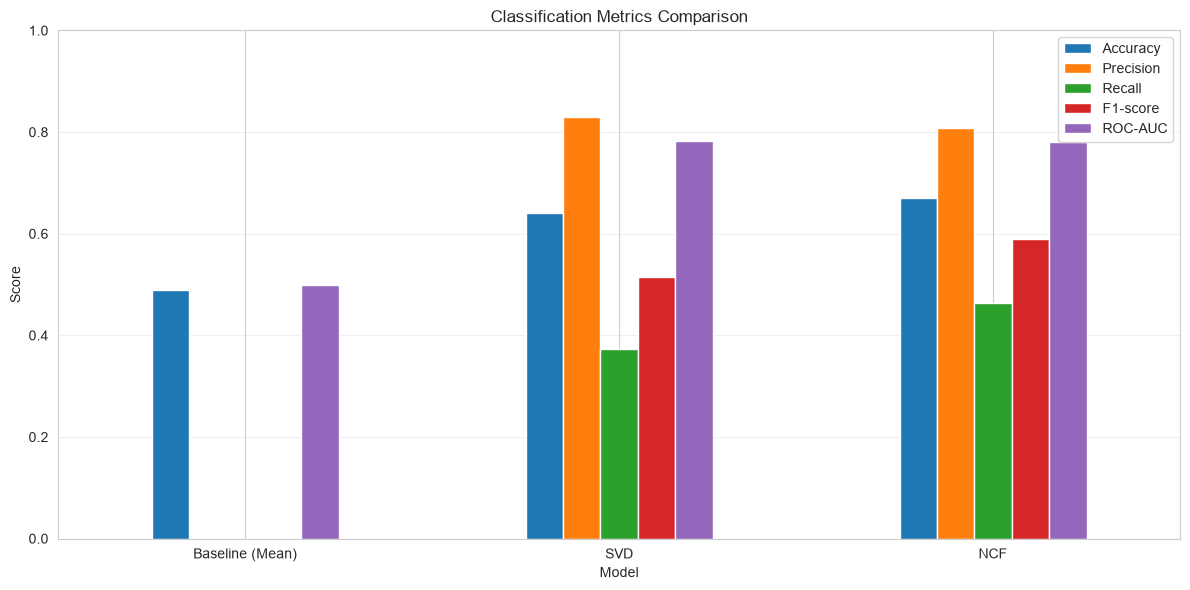

In [15]:
metrics = [
    "Accuracy", "Precision", "Recall",
    "F1-score", "ROC-AUC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Classification Metrics Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Cell 5: Display the three confusion matrices

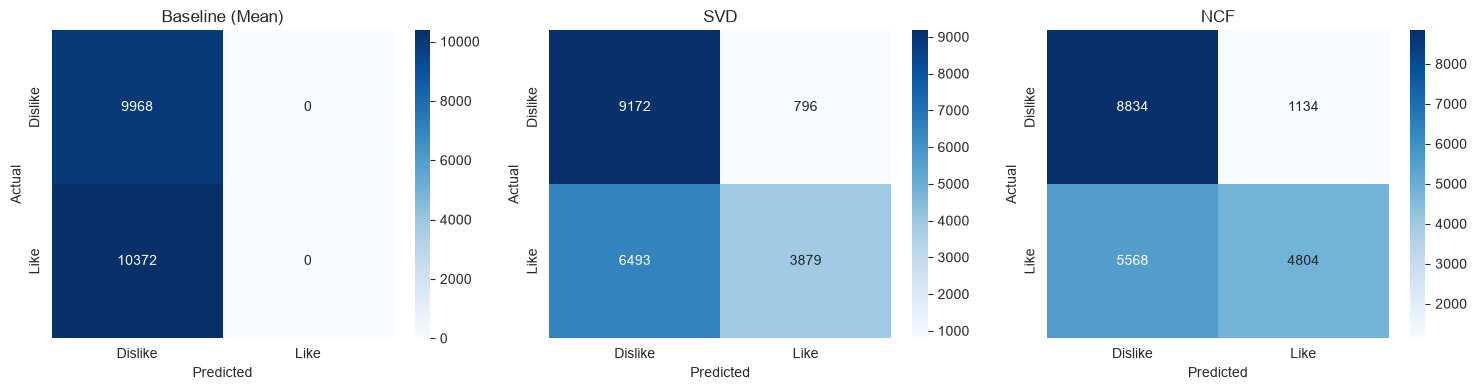

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (model_name, scores) in zip(
    axes, predictions.items()
):
    y_pred = (scores >= THRESHOLD).astype(int)

    cm = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Dislike", "Like"],
        yticklabels=["Dislike", "Like"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## Cell 6: Compare the ROC curves

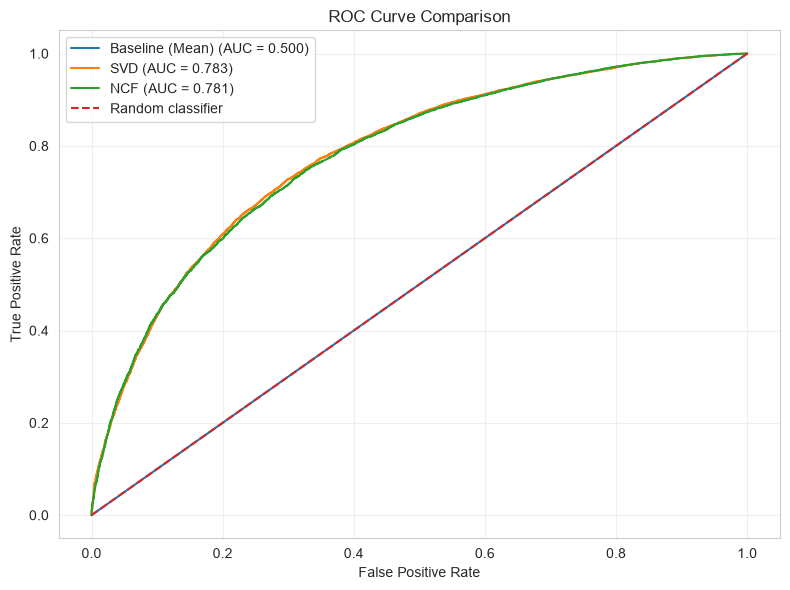

In [17]:
plt.figure(figsize=(8, 6))

if y_true.nunique() == 2:

    for model_name, scores in predictions.items():

        fpr, tpr, _ = roc_curve(y_true, scores)
        auc = roc_auc_score(y_true, scores)

        plt.plot(
            fpr, tpr,
            label=f"{model_name} (AUC = {auc:.3f})"
        )

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        label="Random classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve Comparison")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("ROC curve requires both actual classes.")